## License-Plate-Blurring

**Name:** ***Surya Prakash B***

**Reg No:** ***212224230281***

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
img = cv2.imread('car_plate.jpg')

In [3]:
def display(img):
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

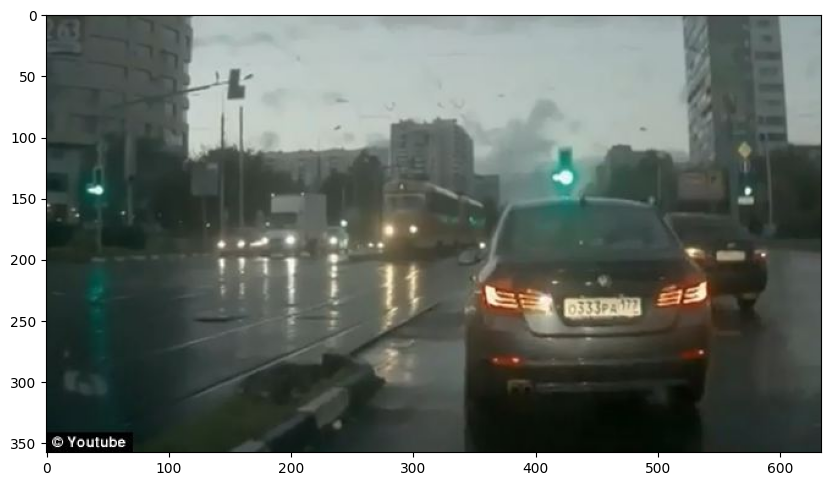

In [4]:
display(img)

In [5]:
plate_cascade = cv2.CascadeClassifier('haarcascade_licence_plate_rus_16stages.xml')

In [6]:
def detect_plate(img):
    plate_img = img.copy()
    
    plate_rects = plate_cascade.detectMultiScale(plate_img) 
    for (x,y,w,h) in plate_rects: 
        cv2.rectangle(plate_img, (x,y), (x+w,y+h), (0,0,255), 2) 
        
    return plate_img

In [7]:
result = detect_plate(img)

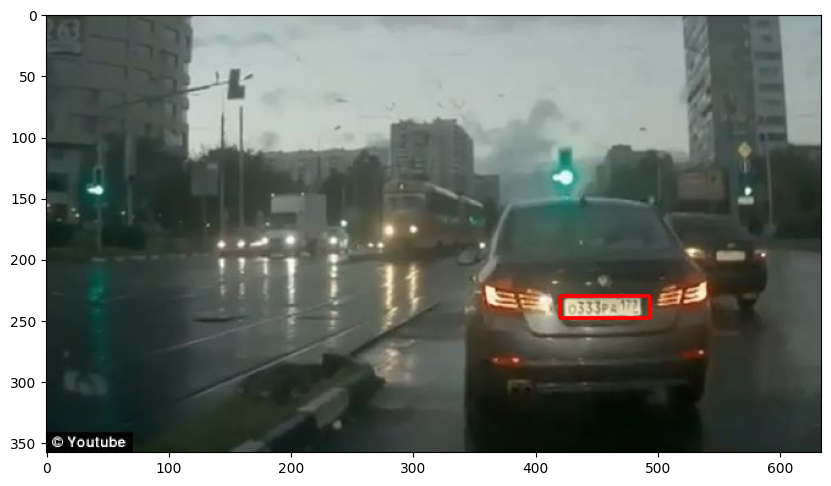

In [8]:
display(result)

In [9]:
def detect_and_blur_plate(img):
    
    plate_img = img.copy()
    
    plate_rects = plate_cascade.detectMultiScale(plate_img)
    
    for (x, y, w, h) in plate_rects:
        roi = plate_img[y:y+h, x:x+w]
        roi = cv2.medianBlur(roi, 35)
        plate_img[y:y+h, x:x+w] = roi
        
    return plate_img

In [10]:
result = detect_and_blur_plate(img)

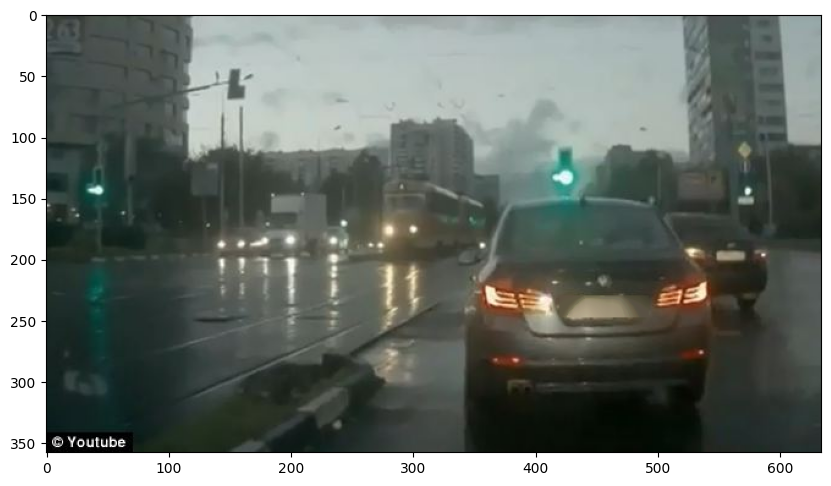

In [11]:
display(result)

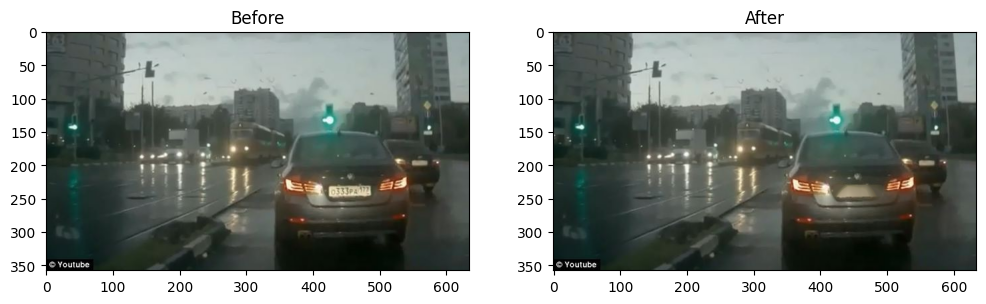

In [12]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Before')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title('After')

plt.show()